# Challenge 2: Decision Tree and Random Forest

David Willaims

My part is Decision Tree and Random Forest. Both models predict whether a visit ends in a purchase (`Revenue=True`).

I used the team's split and compared the default models with the tuned versions. F1 is the main score because most visits do not end in a purchase.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import parallel_config
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, make_scorer, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, ParameterGrid, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
N_JOBS = 4  # Parallelize folds/candidates; each forest uses one worker.
DATA_DIR = Path('.') if Path('challenge2_train.csv').exists() else Path('challenge2')
RESULTS_DIR = DATA_DIR / 'results_trees'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'font.size': 10,
})
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.12.10 | scikit-learn: 1.7.2


## Load and split

Same split and seed as `challenge2_validation_split.ipynb`: 80% for training, 20% held out, and 5-fold cross validation on the training portion.

`ID` is just a row label, so I dropped it. `Revenue` and `Weekend` are converted to 1/0. The row order stays the same so the folds match the other notebooks.

In [2]:
train = pd.read_csv(DATA_DIR / 'challenge2_train.csv')
assert train.shape == (9247, 19), f'Unexpected training shape: {train.shape}'
assert train['ID'].notna().all() and train['ID'].is_unique

def to_01(series):
    """Accept bool, true/false text, or numeric 0/1; reject unknown labels."""
    converted = series.astype(str).str.strip().str.lower().map({
        'true': 1, 'false': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0,
    })
    if converted.isna().any():
        raise ValueError(f'Invalid or missing boolean values in {series.name}')
    return converted.astype(int)

y = to_01(train['Revenue'])
X = train.drop(columns=['ID', 'Revenue']).copy()
X['Weekend'] = to_01(X['Weekend'])
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train))
assert len(X_train) == 7397 and len(X_val) == 1850
assert X_train.index.intersection(X_val.index).empty

print(f'Development: {len(y_train):,} rows, {y_train.sum():,} buyers ({y_train.mean():.2%})')
print(f'Reserved holdout: {len(y_val):,} rows; no predictions or metrics computed')
display(pd.DataFrame({
    'dtype': X_train.dtypes.astype(str),
    'missing': X_train.isna().sum(),
    'unique values': X_train.nunique(),
}))
display(X_train.describe().round(2))

Development: 7,397 rows, 1,145 buyers (15.48%)
Reserved holdout: 1,850 rows; no predictions or metrics computed


,dtype,missing,unique values
Administrative,int64,0,26
Administrative_Duration,float64,0,2228
Informational,int64,0,15
Informational_Duration,float64,0,860
ProductRelated,int64,0,255
ProductRelated_Duration,float64,0,5966
BounceRates,float64,0,1298
ExitRates,float64,0,3105
PageValues,float64,0,1625
SpecialDay,float64,0,6


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend
count,7397.0,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00,7397.00
mean,2.3,80.42,0.50,34.40,31.15,1168.14,0.02,0.04,6.02,0.06,2.13,2.37,3.18,4.05,0.23
std,3.3,174.47,1.25,137.76,42.95,1855.73,0.05,0.05,19.06,0.20,0.91,1.72,2.41,3.99,0.42
min,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,0.00
25%,0.0,0.00,0.00,0.00,7.00,180.17,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00,0.00
50%,1.0,9.00,0.00,0.00,17.00,591.25,0.00,0.03,0.00,0.00,2.00,2.00,3.00,2.00,0.00
75%,4.0,91.33,0.00,0.00,37.00,1458.94,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00,0.00
max,27.0,3398.75,16.00,2549.38,686.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00,1.00


Only about 15.5% of visits are purchases. Predicting "no purchase" every time would give high accuracy but miss every buyer. That is why I use F1 to compare the models.

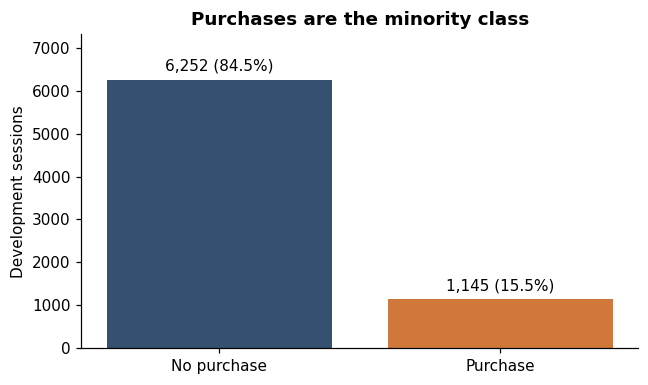

,fold,fit rows,score rows,fit buyer share,score buyer share
0,1,5917,1480,0.1548,0.1547
1,2,5917,1480,0.1548,0.1547
2,3,5918,1479,0.1548,0.1548
3,4,5918,1479,0.1548,0.1548
4,5,5918,1479,0.1548,0.1548


In [3]:
class_counts = y_train.value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(['No purchase', 'Purchase'], class_counts, color=['#355070', '#d0783b'])
ax.bar_label(bars, labels=[f'{n:,} ({n / len(y_train):.1%})' for n in class_counts], padding=4)
ax.set(ylabel='Development sessions', title='Purchases are the minority class', ylim=(0, class_counts.max() * 1.17))
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'class_balance.png', dpi=160)
plt.show()

fold_manifest = pd.DataFrame({'ID': train.loc[X_train.index, 'ID'].to_numpy(), 'fold': 0})
fold_rows = []
for fold_number, (fit_idx, score_idx) in enumerate(folds, 1):
    fold_manifest.loc[score_idx, 'fold'] = fold_number
    fold_rows.append({
        'fold': fold_number, 'fit rows': len(fit_idx), 'score rows': len(score_idx),
        'fit buyer share': y_train.iloc[fit_idx].mean(),
        'score buyer share': y_train.iloc[score_idx].mean(),
    })
assert fold_manifest['fold'].between(1, 5).all()
fold_manifest.to_csv(RESULTS_DIR / 'development_folds.csv', index=False)
display(pd.DataFrame(fold_rows).round(4))

## Preparing the data

`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are treated as categories and one-hot encoded. The other columns stay numeric.

Trees do not need scaling. I included median and most-frequent imputation, although there are no missing values in the training portion. All of this stays inside the pipeline so each fold learns its own preprocessing.

In [4]:
cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
num_cols = [col for col in X.columns if col not in cat_cols]
assert set(num_cols + cat_cols) == set(X.columns)
assert 'ID' not in num_cols + cat_cols and 'Revenue' not in num_cols + cat_cols

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_cols),
])

def make_pipeline(model):
    return Pipeline([('prep', clone(preprocessor)), ('model', model)])

scoring = {
    'f1': make_scorer(f1_score, pos_label=1, zero_division=0),
    'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
    'accuracy': 'accuracy',
}

## Default models

A Decision Tree splits visits into smaller groups using questions about the features. A Random Forest combines many trees built from different samples and feature choices.

First I compare both defaults with a model that always predicts no purchase. The table also shows precision, recall, ROC-AUC, average precision, and accuracy.

The F1 gap is training F1 minus CV F1. A large gap suggests overfitting. The standard deviation shows how much F1 varies across the five folds.

In [5]:
baseline_models = {
    'Always no purchase': make_pipeline(DummyClassifier(strategy='most_frequent')),
    'Decision Tree - default': make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    'Random Forest - default': make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
}

def summarize_cv(name, scores):
    row = {'model': name}
    for metric in scoring:
        row[metric] = float(np.mean(scores[f'test_{metric}']))
        row[f'{metric}_std'] = float(np.std(scores[f'test_{metric}']))
    row['train_f1'] = float(np.mean(scores['train_f1']))
    row['f1_gap'] = row['train_f1'] - row['f1']
    row['mean_fit_seconds'] = float(np.mean(scores['fit_time']))
    return row

comparison_rows = []
baseline_cv = {}
for name, model in baseline_models.items():
    # Use threads for outer parallelism to avoid process/temp-file cleanup issues.
    with parallel_config(backend='threading'):
        scores = cross_validate(
            model, X_train, y_train, cv=folds, scoring=scoring,
            return_train_score=True, n_jobs=N_JOBS, error_score='raise',
        )
    baseline_cv[name] = scores
    comparison_rows.append(summarize_cv(name, scores))

show_cols = ['f1', 'f1_std', 'precision', 'recall', 'average_precision', 'roc_auc',
             'accuracy', 'train_f1', 'f1_gap', 'mean_fit_seconds']
display(pd.DataFrame(comparison_rows).set_index('model')[show_cols].round(4))

,f1,f1_std,precision,recall,average_precision,roc_auc,accuracy,train_f1,f1_gap,mean_fit_seconds
model,,,,,,,,,,
Always no purchase,0.0000,0.0000,0.0000,0.0000,0.1548,0.5000,0.8452,0.0,0.0000,0.0426
Decision Tree - default,0.5564,0.0082,0.5569,0.5563,0.3784,0.7375,0.8626,1.0,0.4436,0.0718
Random Forest - default,0.6513,0.0201,0.7754,0.5616,0.7516,0.9282,0.9069,1.0,0.3487,0.5108


# Decision Tree

The default tree has training F1 of 1.0000 but CV F1 of 0.5564, so it is fitting the training rows too closely.

### Tune the tree

Settings searched:

- **criterion**: gini or entropy, which measure how well a split separates the classes.
- **max_depth**: limits how deep the tree can grow.
- **min_samples_leaf**: sets the minimum number of rows in a leaf.
- **class_weight**: tests whether giving buyers more weight helps.
- **ccp_alpha**: controls pruning; a larger value removes more branches.

This grid has 128 combinations times 5 folds. `refit="f1"` picks the settings with the best mean F1 for the purchase class.

In [6]:
dt_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [4, 6, 10, None],
    'model__min_samples_leaf': [1, 5, 15, 30],
    'model__class_weight': [None, 'balanced'],
    'model__ccp_alpha': [0.0, 0.001],
}
dt_search = GridSearchCV(
    baseline_models['Decision Tree - default'], dt_grid,
    scoring=scoring, refit='f1', cv=folds, n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
print(f'Decision Tree: {len(list(ParameterGrid(dt_grid)))} combinations x 5 folds')
started = perf_counter()
with parallel_config(backend='threading'):
    dt_search.fit(X_train, y_train)
dt_seconds = perf_counter() - started
print(f'Search finished in {dt_seconds:.1f} seconds')
print('Best parameters:', dt_search.best_params_)
print(f'Best development CV F1: {dt_search.best_score_:.4f}')

Decision Tree: 128 combinations x 5 folds


Search finished in 28.2 seconds
Best parameters: {'model__ccp_alpha': 0.001, 'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 6, 'model__min_samples_leaf': 15}
Best development CV F1: 0.6775


In [7]:
def search_summary(name, search):
    idx = search.best_index_
    scores = {}
    for metric in scoring:
        scores[f'test_{metric}'] = [search.cv_results_[f'split{k}_test_{metric}'][idx] for k in range(5)]
    scores['train_f1'] = [search.cv_results_[f'split{k}_train_f1'][idx] for k in range(5)]
    scores['fit_time'] = [search.cv_results_['mean_fit_time'][idx]]
    return summarize_cv(name, scores)

def top_settings(search):
    results = pd.DataFrame(search.cv_results_).sort_values(['rank_test_f1', 'mean_fit_time'])
    cols = [c for c in results if c.startswith('param_')]
    return results[cols + ['mean_test_f1', 'std_test_f1', 'mean_train_f1',
                          'mean_test_precision', 'mean_test_recall']].head(10)

comparison_rows.append(search_summary('Decision Tree - tuned', dt_search))
display(top_settings(dt_search).reset_index(drop=True).round(4))
pd.DataFrame(dt_search.cv_results_).to_csv(RESULTS_DIR / 'decision_tree_grid.csv', index=False)

,param_model__ccp_alpha,param_model__class_weight,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_test_f1,std_test_f1,mean_train_f1,mean_test_precision,mean_test_recall
0,0.001,None,entropy,6,15,0.6775,0.0347,0.7138,0.7086,0.6515
1,0.001,None,entropy,6,5,0.6748,0.0333,0.7137,0.7114,0.6445
2,0.000,None,entropy,10,30,0.6712,0.0262,0.7167,0.7210,0.6288
3,0.001,None,entropy,None,15,0.6707,0.0259,0.7139,0.7187,0.6297
4,0.001,None,entropy,10,15,0.6707,0.0259,0.7139,0.7187,0.6297
5,0.001,None,entropy,6,1,0.6704,0.0265,0.7167,0.7078,0.6384
6,0.001,None,entropy,6,30,0.6702,0.0267,0.7061,0.7198,0.6279
7,0.000,None,entropy,6,30,0.6701,0.0341,0.7109,0.7134,0.6332
8,0.000,None,entropy,None,30,0.6690,0.0254,0.7167,0.7181,0.6271
9,0.001,None,entropy,None,30,0.6674,0.0216,0.7032,0.7264,0.6175


# Random Forest

The default forest does better than the default tree: CV F1 is 0.6513. Its training F1 is still 1.0000, so there is room to reduce overfitting.

### Tune the forest

Settings searched:

- **n_estimators**: how many trees to build.
- **max_depth**: limits the depth of each tree.
- **min_samples_leaf**: keeps leaves from getting too small.
- **max_features**: how many features each split can consider.
- **class_weight**: gives more weight to buyers when set to `"balanced"`.

This grid has 48 combinations times 5 folds. It also selects settings by F1. I kept the normal prediction rule for both models instead of tuning a separate threshold.

In [8]:
rf_grid = {
    'model__n_estimators': [100, 300],
    'model__max_depth': [8, None],
    'model__min_samples_leaf': [1, 4, 10],
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [None, 'balanced'],
}
rf_search = GridSearchCV(
    baseline_models['Random Forest - default'], rf_grid,
    scoring=scoring, refit='f1', cv=folds, n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
print(f'Random Forest: {len(list(ParameterGrid(rf_grid)))} combinations x 5 folds')
started = perf_counter()
with parallel_config(backend='threading'):
    rf_search.fit(X_train, y_train)
rf_seconds = perf_counter() - started
print(f'Search finished in {rf_seconds:.1f} seconds')
print('Best parameters:', rf_search.best_params_)
print(f'Best development CV F1: {rf_search.best_score_:.4f}')
comparison_rows.append(search_summary('Random Forest - tuned', rf_search))
display(top_settings(rf_search).reset_index(drop=True).round(4))
pd.DataFrame(rf_search.cv_results_).to_csv(RESULTS_DIR / 'random_forest_grid.csv', index=False)

Random Forest: 48 combinations x 5 folds


Search finished in 103.5 seconds
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 4, 'model__n_estimators': 300}
Best development CV F1: 0.7051


,param_model__class_weight,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,param_model__n_estimators,mean_test_f1,std_test_f1,mean_train_f1,mean_test_precision,mean_test_recall
0,balanced,None,0.5,4,300,0.7051,0.0322,0.8795,0.6588,0.7590
1,balanced,None,0.5,4,100,0.6982,0.0307,0.8767,0.6534,0.7502
2,balanced,None,sqrt,4,300,0.6956,0.0319,0.8191,0.6291,0.7782
3,balanced,None,sqrt,4,100,0.6949,0.0338,0.8202,0.6285,0.7773
4,balanced,None,0.5,10,300,0.6937,0.0274,0.7652,0.6072,0.8096
5,balanced,8,0.5,4,300,0.6921,0.0289,0.7569,0.6043,0.8105
6,balanced,None,0.5,10,100,0.6919,0.0257,0.7656,0.6034,0.8114
7,balanced,8,0.5,1,100,0.6903,0.0284,0.7696,0.6054,0.8035
8,balanced,8,0.5,10,300,0.6903,0.0282,0.7338,0.5951,0.8227
9,balanced,8,0.5,1,300,0.6881,0.0280,0.7730,0.6030,0.8017


## Comparison

Both models before and after tuning. The F1 column is the average of the five fold scores.

These folds were also used to pick the settings, so the tuned scores may be a little optimistic. The team's hold-out is still needed for the final check. Average precision is shown separately from ROC-AUC.

,f1,f1_std,precision,recall,average_precision,roc_auc,accuracy,train_f1,f1_gap,mean_fit_seconds
model,,,,,,,,,,
Random Forest - tuned,0.7051,0.0322,0.6588,0.7590,0.7638,0.9350,0.9016,0.8795,0.1744,3.0451
Decision Tree - tuned,0.6775,0.0347,0.7086,0.6515,0.7021,0.9237,0.9044,0.7138,0.0363,0.0608
Random Forest - default,0.6513,0.0201,0.7754,0.5616,0.7516,0.9282,0.9069,1.0000,0.3487,0.5108
Decision Tree - default,0.5564,0.0082,0.5569,0.5563,0.3784,0.7375,0.8626,1.0000,0.4436,0.0718
Always no purchase,0.0000,0.0000,0.0000,0.0000,0.1548,0.5000,0.8452,0.0000,0.0000,0.0426


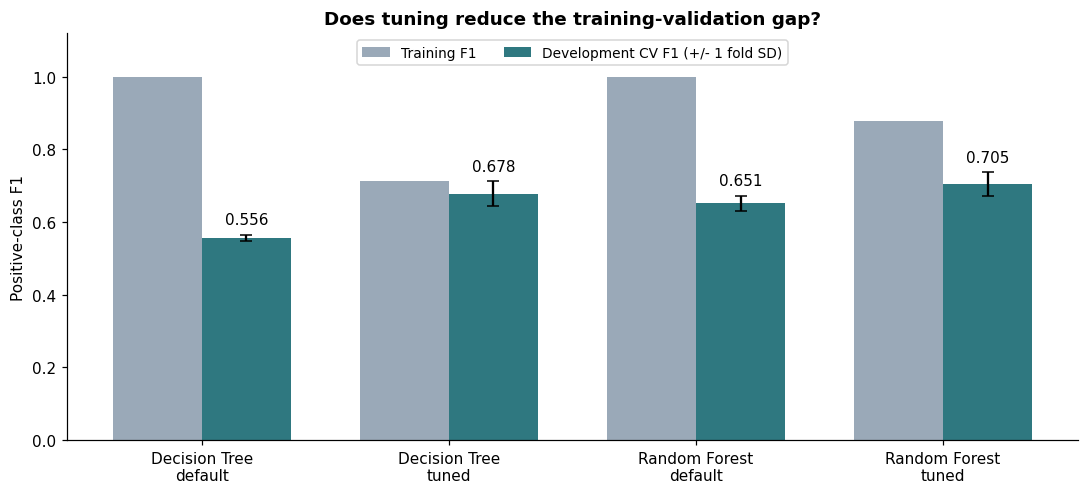

Decision Tree: CV F1 0.5564 -> 0.6775; train-CV gap 0.4436 -> 0.0363
Random Forest: CV F1 0.6513 -> 0.7051; train-CV gap 0.3487 -> 0.1744


In [9]:
comparison = pd.DataFrame(comparison_rows).set_index('model')
comparison = comparison.sort_values('f1', ascending=False, kind='stable')
display(comparison[show_cols].round(4))
comparison.to_csv(RESULTS_DIR / 'model_comparison.csv')

names = ['Decision Tree - default', 'Decision Tree - tuned',
         'Random Forest - default', 'Random Forest - tuned']
chart_data = comparison.loc[names]
fig, ax = plt.subplots(figsize=(10, 4.6))
positions = np.arange(len(names))
ax.bar(positions - 0.18, chart_data['train_f1'], width=0.36, label='Training F1', color='#9aa9b8')
bars = ax.bar(positions + 0.18, chart_data['f1'], width=0.36,
             yerr=chart_data['f1_std'], capsize=4, label='Development CV F1 (+/- 1 fold SD)', color='#2f7880')
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.set_xticks(positions, [name.replace(' - ', '\n') for name in names])
ax.set(ylabel='Positive-class F1', ylim=(0, 1.12), title='Does tuning reduce the training-validation gap?')
ax.legend(loc='upper center', ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'model_comparison.png', dpi=160)
plt.show()

for family in ['Decision Tree', 'Random Forest']:
    default = comparison.loc[f'{family} - default']
    tuned = comparison.loc[f'{family} - tuned']
    print(f'{family}: CV F1 {default.f1:.4f} -> {tuned.f1:.4f}; '
          f'train-CV gap {default.f1_gap:.4f} -> {tuned.f1_gap:.4f}')

## Confusion matrices

Each training row gets a prediction from a model fitted on the other four folds. False positives are visits predicted to buy that did not buy. False negatives are buyers the model missed.

The F1 shown here combines all fold predictions, so it can differ slightly from the average F1 in the comparison table. These are still development results because the settings were chosen using these same folds.

Decision Tree - tuned
              precision    recall  f1-score   support

 No purchase      0.937     0.951     0.944      6252
    Purchase      0.708     0.652     0.678      1145

    accuracy                          0.904      7397
   macro avg      0.822     0.801     0.811      7397
weighted avg      0.902     0.904     0.903      7397



Random Forest - tuned
              precision    recall  f1-score   support

 No purchase      0.955     0.928     0.941      6252
    Purchase      0.658     0.759     0.705      1145

    accuracy                          0.902      7397
   macro avg      0.806     0.843     0.823      7397
weighted avg      0.909     0.902     0.904      7397



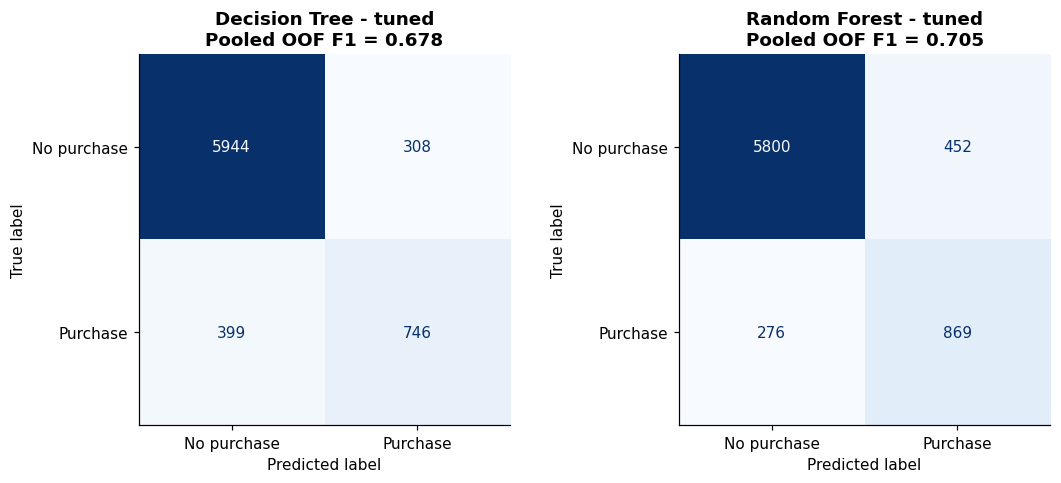

In [10]:
tuned_models = {
    'Decision Tree - tuned': dt_search.best_estimator_,
    'Random Forest - tuned': rf_search.best_estimator_,
}
oof_diagnostics = {}
oof_export = pd.DataFrame({'ID': train.loc[X_train.index, 'ID'].to_numpy(),
                           'Revenue': y_train.to_numpy()})
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, model) in zip(axes, tuned_models.items()):
    predictions = np.empty(len(y_train), dtype=int)
    probabilities = np.empty(len(y_train), dtype=float)
    seen = np.zeros(len(y_train), dtype=int)
    for fit_idx, score_idx in folds:
        fold_model = clone(model).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        predictions[score_idx] = fold_model.predict(X_train.iloc[score_idx])
        positive_col = list(fold_model.classes_).index(1)
        probabilities[score_idx] = fold_model.predict_proba(X_train.iloc[score_idx])[:, positive_col]
        seen[score_idx] += 1
    assert np.all(seen == 1)
    oof_diagnostics[name] = {
        'pooled_f1': float(f1_score(y_train, predictions)),
        'precision': float(precision_score(y_train, predictions, zero_division=0)),
        'recall': float(recall_score(y_train, predictions, zero_division=0)),
    }
    prefix = 'decision_tree' if name.startswith('Decision') else 'random_forest'
    oof_export[f'{prefix}_prediction'] = predictions
    oof_export[f'{prefix}_probability'] = probabilities
    ConfusionMatrixDisplay.from_predictions(
        y_train, predictions, labels=[0, 1], display_labels=['No purchase', 'Purchase'],
        cmap='Blues', ax=ax, colorbar=False,
    )
    ax.set_title(f"{name}\nPooled OOF F1 = {oof_diagnostics[name]['pooled_f1']:.3f}")
    print(name)
    print(classification_report(y_train, predictions, target_names=['No purchase', 'Purchase'], digits=3, zero_division=0))
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'oof_confusion_matrices.png', dpi=160)
plt.show()
oof_export.to_csv(RESULTS_DIR / 'development_oof_predictions.csv', index=False)

## Tree and feature importance

The diagram shows the first three levels of the tuned tree. The full tree has depth 6 and 22 leaves.

The importance chart combines the one-hot columns back into their original features. It shows which inputs the models used most. Impurity-based importance can favor features with more possible splits, and related features can share importance. It does not show cause and effect.

Selected Decision Tree depth: 6 | leaves: 22


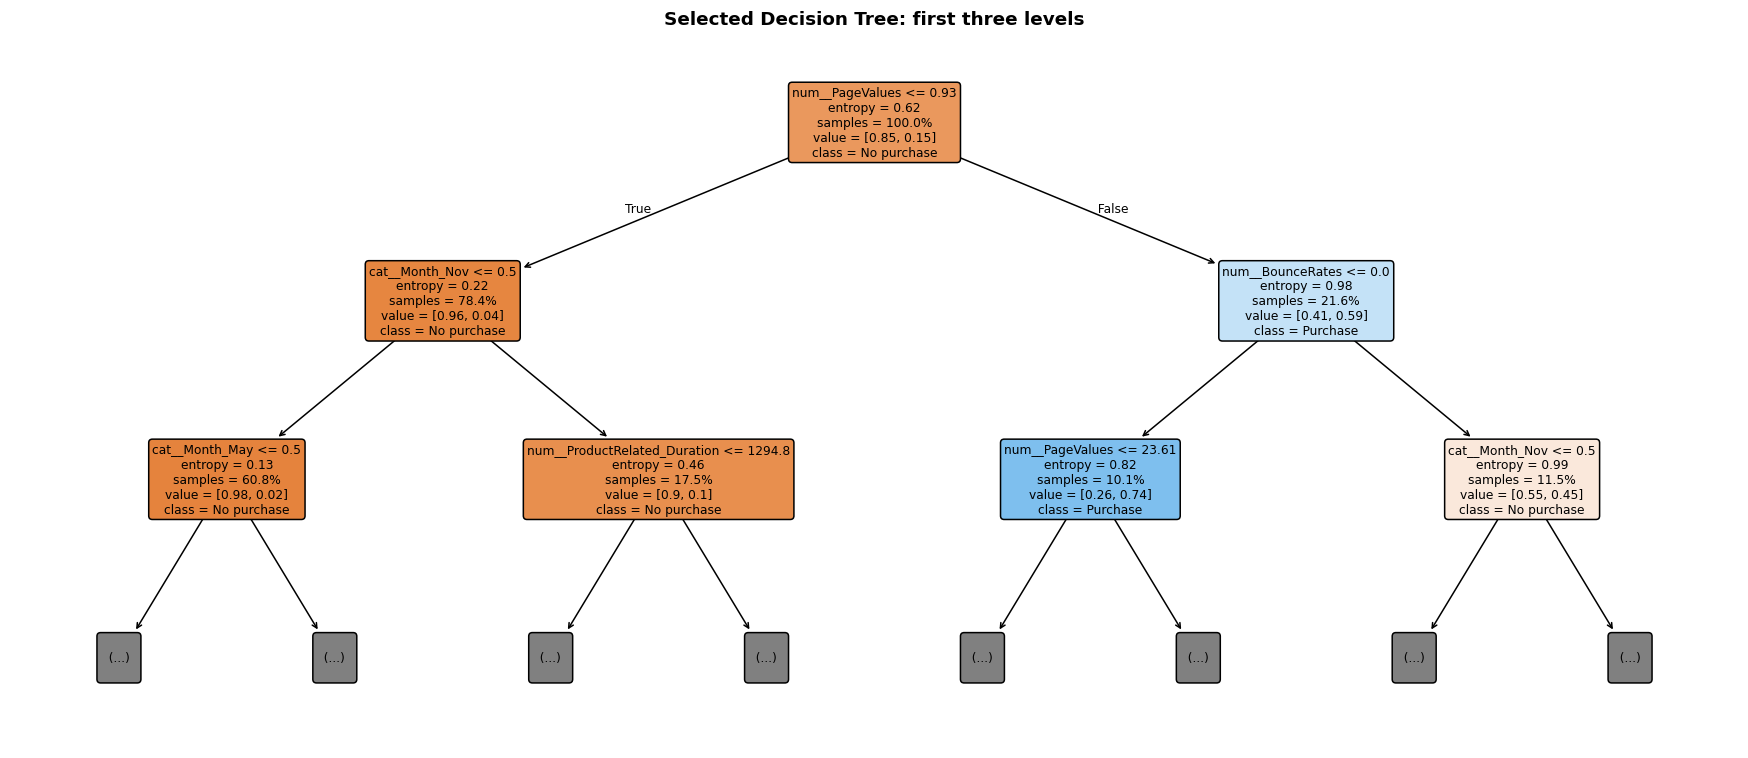

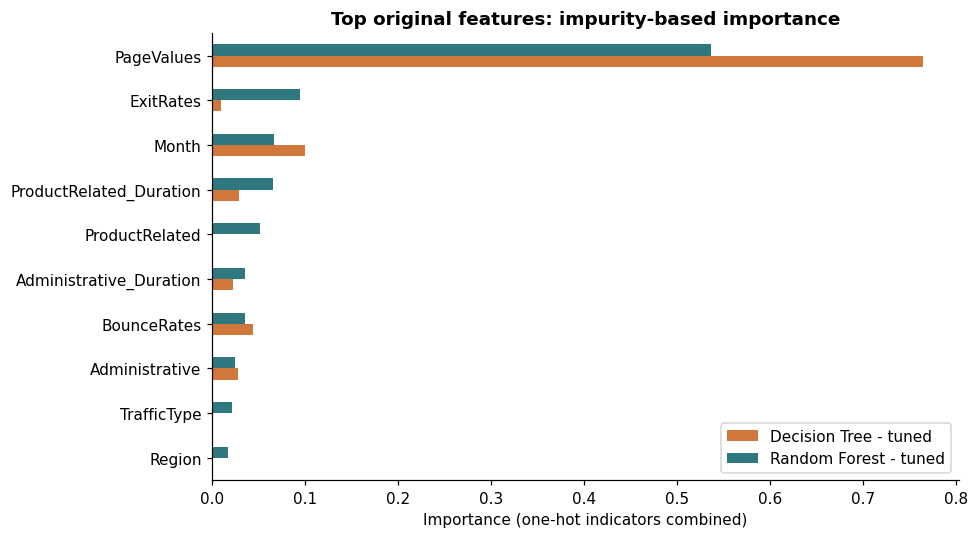

In [11]:
dt_model = dt_search.best_estimator_.named_steps['model']
dt_features = dt_search.best_estimator_.named_steps['prep'].get_feature_names_out()
print('Selected Decision Tree depth:', dt_model.get_depth(), '| leaves:', dt_model.get_n_leaves())
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(dt_model, feature_names=dt_features, class_names=['No purchase', 'Purchase'],
          max_depth=2, filled=True, rounded=True, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title('Selected Decision Tree: first three levels')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'decision_tree_preview.png', dpi=160)
plt.show()

importance_columns = {}
for name, pipeline in tuned_models.items():
    encoder = pipeline.named_steps['prep'].named_transformers_['cat'].named_steps['onehot']
    original_features = num_cols + [col for col, categories in zip(cat_cols, encoder.categories_) for _ in categories]
    values = pipeline.named_steps['model'].feature_importances_
    assert len(original_features) == len(values)
    importance_columns[name] = pd.Series(values, index=original_features).groupby(level=0).sum()
importance_table = pd.DataFrame(importance_columns)
importance_table.to_csv(RESULTS_DIR / 'feature_importance.csv')
importance_table.sort_values('Random Forest - tuned').tail(10).plot.barh(
    figsize=(9, 5), color=['#d0783b', '#2f7880'], title='Top original features: impurity-based importance',
)
plt.xlabel('Importance (one-hot indicators combined)')
plt.ylabel('')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_importance.png', dpi=160)
plt.show()

## Summary

Tuning improved both models:

| Model | Default CV F1 | Tuned CV F1 |
|---|---:|---:|
| Decision Tree | 0.5564 | 0.6775 |
| Random Forest | 0.6513 | 0.7051 |

I would bring the tuned Random Forest to the team's final comparison. Its recall is about 0.759, compared with 0.652 for the tuned tree, so it finds more buyers. Its precision is lower, meaning it also predicts more purchases that do not happen.

The Decision Tree is easier to explain and has a much smaller training-CV gap after pruning: 0.0363 compared with 0.1744 for the forest. The forest still shows some overfitting and takes longer to fit, but it has the better F1 of these two.

The team still needs to compare this with the other models before choosing the final one. The difference in CV scores alone does not prove one will always perform better on new data.

In [12]:
candidate_models = {name: model for name, model in baseline_models.items() if name != 'Always no purchase'}
candidate_models.update(tuned_models)
recommended_name = comparison.loc[list(candidate_models)].sort_values('f1', ascending=False, kind='stable').index[0]
recommended = comparison.loc[recommended_name]
display(Markdown(
    f'**Tree-family recommendation: {recommended_name}.** Mean development CV F1: '
    f'**{recommended.f1:.4f}** (fold SD {recommended.f1_std:.4f}); '
    f'precision {recommended.precision:.4f}; recall {recommended.recall:.4f}. '
    f'Training F1 is {recommended.train_f1:.4f}, giving a training-CV gap of {recommended.f1_gap:.4f}.'
))

run_summary = {
    'source_branch': 'Teamwork2',
    'source_commit': 'b153b543c8d36e3cf24a115865694ab7e19ac3bf',
    'training_csv_sha256_normalized_lf': hashlib.sha256(
        (DATA_DIR / 'challenge2_train.csv').read_bytes().replace(b'\r\n', b'\n')
    ).hexdigest(),
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    'random_state': RANDOM_STATE, 'holdout_fraction': 0.20,
    'development_rows': len(X_train), 'holdout_rows': len(X_val),
    'cv_folds': 5, 'selection_metric': 'positive_class_mean_fold_f1',
    'threshold_tuned': False, 'holdout_evaluated': False, 'test_data_loaded': False,
    'decision_tree_best_params': dt_search.best_params_,
    'random_forest_best_params': rf_search.best_params_,
    'decision_tree_grid_combinations': len(list(ParameterGrid(dt_grid))),
    'random_forest_grid_combinations': len(list(ParameterGrid(rf_grid))),
    'search_seconds': {'decision_tree': dt_seconds, 'random_forest': rf_seconds},
    'recommended_tree_candidate': recommended_name,
    'development_oof_diagnostics': oof_diagnostics,
    'limitation': 'Hyperparameters selected using these CV folds; independent holdout is reserved for team final choice.',
}
(RESULTS_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2), encoding='utf-8')
print('Saved comparison, grids, folds, diagnostics, charts, and reproducibility information to', RESULTS_DIR)

**Tree-family recommendation: Random Forest - tuned.** Mean development CV F1: **0.7051** (fold SD 0.0322); precision 0.6588; recall 0.7590. Training F1 is 0.8795, giving a training-CV gap of 0.1744.

Saved comparison, grids, folds, diagnostics, charts, and reproducibility information to results_trees


## Final predictions, if the team selects one of these models

This cell is off for now. After the team picks a final model, set `RUN_FINAL_EXPORT=True` and enter its name in `FINAL_MODEL_NAME`.

It scores that fixed model once on the hold-out, refits on all 9,247 training rows, and then loads the test file to write `results_trees/predictions.csv`. The file contains `ID` and `Revenue` as True/False in the original test order.

Do not use the hold-out score to keep changing the model. If the team picks a different model, leave this cell off.

In [13]:
RUN_FINAL_EXPORT = False
FINAL_MODEL_NAME = None  # Example: 'Random Forest - tuned'; choose only after team comparison.

if RUN_FINAL_EXPORT:
    if FINAL_MODEL_NAME not in candidate_models:
        raise ValueError('Set FINAL_MODEL_NAME to the fixed model selected by the team.')
    chosen_pipeline = clone(candidate_models[FINAL_MODEL_NAME])
    chosen_pipeline.fit(X_train, y_train)
    holdout_prediction = chosen_pipeline.predict(X_val)
    positive_col = list(chosen_pipeline.classes_).index(1)
    holdout_probability = chosen_pipeline.predict_proba(X_val)[:, positive_col]
    holdout_metrics = {
        'model': FINAL_MODEL_NAME,
        'f1': f1_score(y_val, holdout_prediction),
        'precision': precision_score(y_val, holdout_prediction, zero_division=0),
        'recall': recall_score(y_val, holdout_prediction, zero_division=0),
        'accuracy': accuracy_score(y_val, holdout_prediction),
        'roc_auc': roc_auc_score(y_val, holdout_probability),
        'average_precision': average_precision_score(y_val, holdout_probability),
    }
    display(pd.Series(holdout_metrics))
    ConfusionMatrixDisplay.from_predictions(y_val, holdout_prediction, labels=[0, 1])
    plt.title('Final fixed model: reserved holdout')
    plt.show()

    final_model = clone(candidate_models[FINAL_MODEL_NAME]).fit(X, y)
    test = pd.read_csv(DATA_DIR / 'challenge2_test.csv')
    assert 'Revenue' not in test.columns, 'The challenge test file must not contain labels.'
    assert len(test) == 3083 and test['ID'].notna().all() and test['ID'].is_unique
    assert set(test.columns) == set(X.columns) | {'ID'}
    X_test = test.drop(columns='ID').copy()
    X_test['Weekend'] = to_01(X_test['Weekend'])
    X_test = X_test.loc[:, X.columns]
    final_classes = final_model.predict(X_test)
    predictions = pd.DataFrame({
        'ID': test['ID'], 'Revenue': np.where(final_classes == 1, 'True', 'False'),
    })
    assert predictions['ID'].equals(test['ID'])
    assert predictions['Revenue'].isin(['True', 'False']).all()
    predictions.to_csv(RESULTS_DIR / 'predictions.csv', index=False)
    (RESULTS_DIR / 'final_holdout_metrics.json').write_text(json.dumps(holdout_metrics, indent=2), encoding='utf-8')
    run_summary.update({'holdout_evaluated': True, 'test_data_loaded': True, 'final_model': FINAL_MODEL_NAME})
    (RESULTS_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2), encoding='utf-8')
    print('Wrote', len(predictions), 'predictions to', RESULTS_DIR / 'predictions.csv')
else:
    print('Development complete. Shared holdout and challenge test data remain unused.')

Development complete. Shared holdout and challenge test data remain unused.
